# Aandelenportfolio met R

In [1]:
install.packages("tidyquant")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘globals’, ‘listenv’, ‘parallelly’, ‘mvtnorm’, ‘pcaPP’, ‘DEoptimR’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘furrr’, ‘crosstalk’, ‘warp’, ‘BH’, ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘urca’, ‘RcppArmadillo’, ‘RcppRoll’, ‘tseries’, ‘future’, ‘quadprog’, ‘pyinit’, ‘rrcov’, ‘robustbase’, ‘recipes’, ‘rsample’, ‘plotly’, ‘padr’, ‘slider’, ‘anytime’, ‘forecast’, ‘tsfeatures’, ‘lazyeval’, ‘PerformanceAnalytics’, ‘RobStatTM’, ‘quantmod’, ‘timetk’, ‘timeDate’, ‘TTR’, ‘xts’, ‘zoo’




In [2]:
library(tidyquant)

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

── Attaching core tidyquant packages ─────────────────────── tidyquant 1.0.12 ──
✔ PerformanceAnalytics 2.1.0      ✔ TTR                  0.24.4
✔ quantmod             0.4.28     ✔ xts                  0.14.2
── Conflicts ────────────────────────────────────────── tidyquant_conflicts() ──
✖ zoo::as.Date()                 masks base::as.Date()
✖ zoo::as.Date.numeric()         masks base::as.Date.numeric()
✖ PerformanceAnalytics::legend() masks graphics::legend()
✖ quantmod::summary()            masks base::summary()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::first()  masks xts::first()
✖ dplyr::lag()    masks stats::lag()
✖ dplyr::last()   masks xts::last()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [4]:
aapl <- tq_get("AAPL", from = "2017-01-01", to = Sys.Date())

Nu we de gegevens hebben geladen, kunnen we de laatste paar rijen bekijken om een idee te krijgen van de structuur.

In [6]:
tail(aapl)

symbol,date,open,high,low,close,volume,adjusted
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2026-05-26,309.56,311.82,307.67,308.33,48000500,308.33
AAPL,2026-05-27,308.33,313.26,308.30,310.85,50430900,310.85
AAPL,2026-05-28,310.68,312.80,309.57,312.51,48220400,312.51
AAPL,2026-05-29,311.78,315.00,309.53,312.06,70026800,312.06
AAPL,2026-06-01,309.63,310.94,305.02,306.31,48849900,306.31
AAPL,2026-06-02,307.46,315.45,306.69,315.20,44416900,315.20


Laten we nu een samenvatting van de data bekijken om een algemeen beeld te krijgen van de statistische eigenschappen van de kolommen.

In [7]:
summary(aapl)

       symbol          date                 open             high       
 Length   :2366   Min.   :2017-01-03   Min.   : 28.95   Min.   : 29.08  
 N.unique :   1   1st Qu.:2019-05-10   1st Qu.: 51.97   1st Qu.: 52.32  
 N.blank  :   0   Median :2021-09-14   Median :140.36   Median :142.55  
 Min.nchar:   4   Mean   :2021-09-14   Mean   :132.74   Mean   :134.19  
 Max.nchar:   4   3rd Qu.:2024-01-22   3rd Qu.:186.62   3rd Qu.:188.25  
                  Max.   :2026-06-02   Max.   :311.78   Max.   :315.45  
      low             close            volume             adjusted     
 Min.   : 28.69   Min.   : 29.00   Min.   : 17910600   Min.   : 26.69  
 1st Qu.: 51.67   1st Qu.: 52.03   1st Qu.: 55764525   1st Qu.: 49.53  
 Median :138.18   Median :140.67   Median : 81863600   Median :137.75  
 Mean   :131.41   Mean   :132.87   Mean   : 93849351   Mean   :130.50  
 3rd Qu.:184.57   3rd Qu.:186.81   3rd Qu.:113823100   3rd Qu.:184.61  
 Max.   :309.57   Max.   :315.20   Max.   :447940000   Ma

Nu we de data hebben geladen en samengevat, is het tijd om de koers van Apple te visualiseren. We maken een lijngrafiek om de trend van de 'adjusted close' prijs over tijd te zien, met specifieke aanpassingen aan de y-as.

Warning message:
“Removed 9 rows containing missing values or values outside the scale range
(`geom_line()`).”


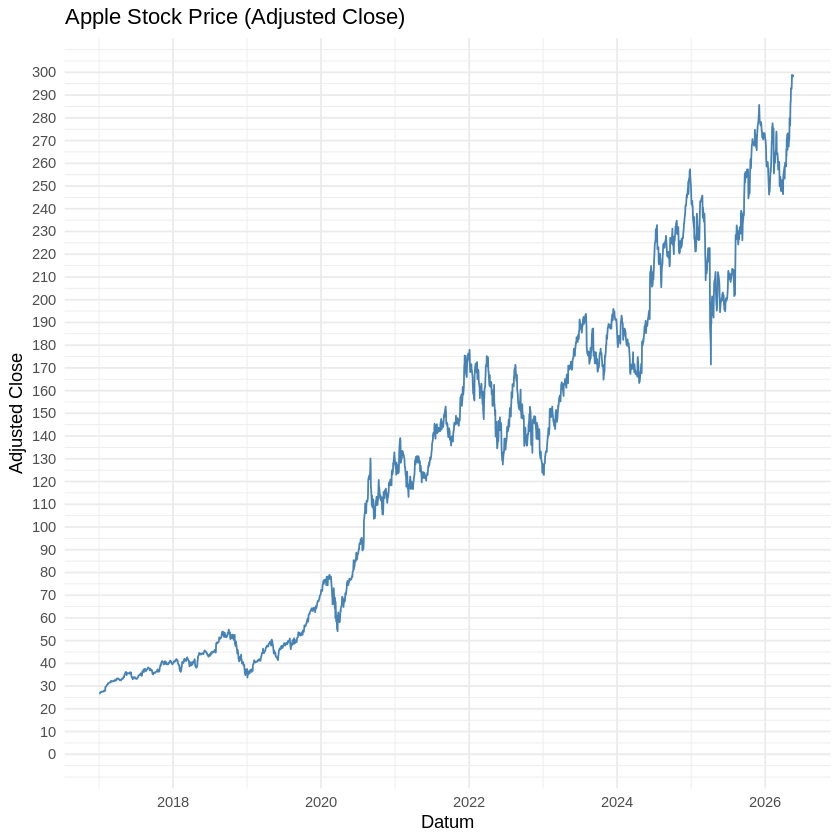

In [8]:
ggplot(aapl, aes(x = date, y = adjusted)) +
  geom_line(color = "steelblue") +
  scale_y_continuous(limits = c(0, 300), breaks = seq(0, 300, by = 10)) +
  labs(
    title = "Apple Stock Price (Adjusted Close)",
    x = "Datum",
    y = "Adjusted Close"
  ) +
  theme_minimal()

Hier zijn 5 voorbeeld ticker-symbolen:

*   **AAPL**: Apple Inc.
*   **MSFT**: Microsoft Corporation
*   **GOOGL**: Alphabet Inc. (Google)
*   **AMZN**: Amazon.com Inc.
*   **TSLA**: Tesla, Inc.

Nu gaan we de koersdata voor een portfolio van 5 aandelen (Apple, Microsoft, Alphabet, Amazon, Tesla) inlezen. We gebruiken dezelfde periode als voorheen, van 1 januari 2017 tot vandaag.

In [9]:
tickers <- c("AAPL", "MSFT", "GOOGL", "AMZN", "TSLA")
portfolio <- tq_get(tickers, from = "2017-01-01", to = Sys.Date())

Laten we de eerste paar rijen van de `portfolio` data bekijken om te controleren of alle tickers succesvol zijn ingelezen.

In [10]:
head(portfolio)

symbol,date,open,high,low,close,volume,adjusted
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2017-01-03,28.9500,29.0825,28.6900,29.0375,115127600,26.72124
AAPL,2017-01-04,28.9625,29.1275,28.9375,29.0050,84472400,26.69133
AAPL,2017-01-05,28.9800,29.2150,28.9525,29.1525,88774400,26.82706
AAPL,2017-01-06,29.1950,29.5400,29.1175,29.4775,127007600,27.12614
AAPL,2017-01-09,29.4875,29.8575,29.4850,29.7475,134247600,27.37460
AAPL,2017-01-10,29.6925,29.8450,29.5750,29.7775,97848400,27.40221


Laten we nu een gecombineerde grafiek maken van de 'adjusted close' prijzen voor alle aandelen in de portfolio. Door de grafiek op te splitsen per aandeelsymbool, kunnen we de individuele trends duidelijk waarnemen.

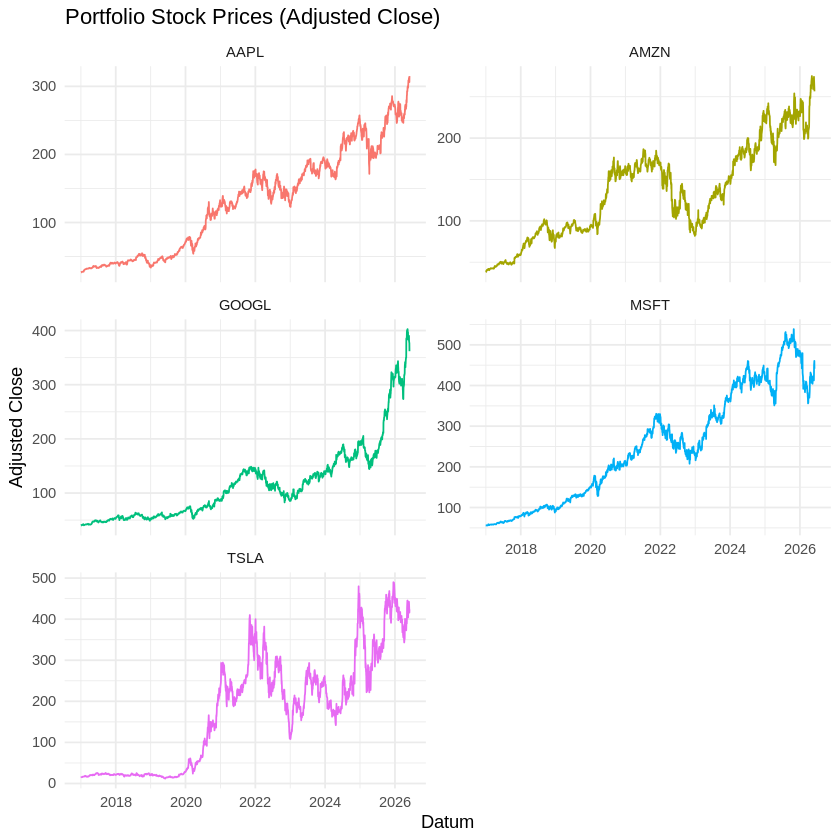

In [11]:
ggplot(portfolio, aes(x = date, y = adjusted, color = symbol)) +
  geom_line() +
  facet_wrap(~ symbol, scales = "free_y", ncol = 2) +
  labs(
    title = "Portfolio Stock Prices (Adjusted Close)",
    x = "Datum",
    y = "Adjusted Close"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

In [13]:
summary(portfolio)

       symbol           date                 open             high       
 Length   :11830   Min.   :2017-01-03   Min.   : 12.07   Min.   : 12.45  
 N.unique :    5   1st Qu.:2019-05-10   1st Qu.: 72.25   1st Qu.: 72.89  
 N.blank  :    0   Median :2021-09-14   Median :143.01   Median :144.58  
 Min.nchar:    4   Mean   :2021-09-14   Mean   :163.28   Mean   :165.39  
 Max.nchar:    5   3rd Qu.:2024-01-23   3rd Qu.:225.70   3rd Qu.:228.85  
                   Max.   :2026-06-02   Max.   :555.23   Max.   :555.45  
      low             close            volume             adjusted     
 Min.   : 11.80   Min.   : 11.93   Min.   :  5855900   Min.   : 11.93  
 1st Qu.: 71.45   1st Qu.: 72.39   1st Qu.: 29970325   1st Qu.: 69.53  
 Median :140.99   Median :142.95   Median : 52505350   Median :141.13  
 Mean   :161.12   Mean   :163.33   Mean   : 68847683   Mean   :161.24  
 3rd Qu.:222.44   3rd Qu.:225.67   3rd Qu.: 89113100   3rd Qu.:223.68  
 Max.   :540.77   Max.   :542.07   Max.   :9140820

### Correlatiematrix van de Aandelen

Laten we de correlatie tussen de 'adjusted close' prijzen van de verschillende aandelen in de portfolio bekijken. Dit geeft inzicht in hoe de prijsbewegingen van de aandelen onderling gerelateerd zijn.

In [14]:
portfolio_wide <- portfolio %>%
  select(date, symbol, adjusted) %>%
  pivot_wider(names_from = symbol, values_from = adjusted)

correlation_matrix <- cor(portfolio_wide %>% select(-date), use = "pairwise.complete.obs")

print(correlation_matrix)

           AAPL      MSFT     GOOGL      AMZN      TSLA
AAPL  1.0000000 0.9638370 0.9095986 0.8988132 0.9290394
MSFT  0.9638370 1.0000000 0.8579190 0.9077463 0.8809818
GOOGL 0.9095986 0.8579190 1.0000000 0.8724911 0.8610025
AMZN  0.8988132 0.9077463 0.8724911 1.0000000 0.8678784
TSLA  0.9290394 0.8809818 0.8610025 0.8678784 1.0000000


De correlatiematrix toont de lineaire relatie tussen de prijsbewegingen van elk paar aandelen. Waarden dicht bij 1 duiden op een sterke positieve correlatie (aandelen bewegen in dezelfde richting), terwijl waarden dicht bij -1 wijzen op een sterke negatieve correlatie (aandelen bewegen in tegengestelde richtingen). Waarden rond 0 betekenen weinig of geen lineaire correlatie.

In [15]:
aapl_2026 <- aapl %>%
  filter(year(date) == 2026)

if (nrow(aapl_2026) > 0) {
  average_price_aapl_2026 <- mean(aapl_2026$adjusted)
  cat(sprintf("De gemiddelde 'adjusted close' koers van Apple in 2026 is: %.2f\n", average_price_aapl_2026))
} else {
  cat("Geen Apple koersdata gevonden voor het jaar 2026 in de huidige dataset.\n")
}

De gemiddelde 'adjusted close' koers van Apple in 2026 is: 269.03


### Standaardafwijking van Nvidia Aandeel

Laten we de koersdata voor Nvidia (NVDA) ophalen en de standaardafwijking van de 'adjusted close' prijs berekenen. Dit geeft ons een idee van de volatiliteit van het aandeel over de gehele periode.

In [16]:
nvda <- tq_get("NVDA", from = "2017-01-01", to = Sys.Date())

if (nrow(nvda) > 0) {
  std_dev_nvda <- sd(nvda$adjusted, na.rm = TRUE)
  cat(sprintf("De standaardafwijking van de 'adjusted close' koers van Nvidia is: %.2f\n", std_dev_nvda))
} else {
  cat("Geen Nvidia koersdata gevonden voor de opgegeven periode.\n")
}

De standaardafwijking van de 'adjusted close' koers van Nvidia is: 60.29


### Volume van Verhandelde Amazon Aandelen

Laten we het handelsvolume van Amazon (AMZN) visualiseren over de gehele periode. Dit kan inzicht geven in de liquiditeit en de interesse in het aandeel over tijd.

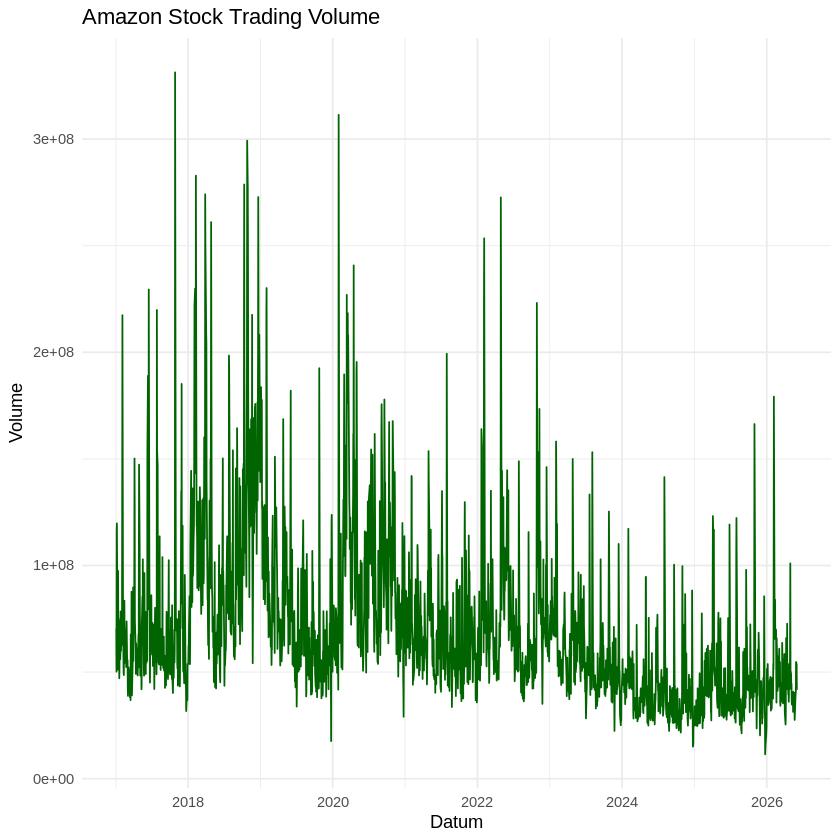

In [17]:
amazon_volume <- portfolio %>%
  filter(symbol == "AMZN")

ggplot(amazon_volume, aes(x = date, y = volume)) +
  geom_line(color = "darkgreen") +
  labs(
    title = "Amazon Stock Trading Volume",
    x = "Datum",
    y = "Volume"
  ) +
  theme_minimal()

### Toetsvragen

1.  **Vraag 1: Volatiliteit van Tesla vs. Microsoft**
    Bereken de standaardafwijking van de 'adjusted close' koers van Tesla (TSLA) en Microsoft (MSFT) voor de gehele periode. Welk aandeel was volatieler en waarom?

2.  **Vraag 2: Correlatie tussen twee specifieke aandelen**
    Selecteer twee aandelen uit de `portfolio` (bijvoorbeeld GOOGL en AMZN) en bereken hun onderlinge correlatie van de 'adjusted close' prijzen. Interpreteer de uitkomst.

3.  **Vraag 3: Maandelijkse gemiddelde koers van Apple**
    Bereken de maandelijkse gemiddelde 'adjusted close' koers van Apple (AAPL) voor het jaar 2023. Presenteer de resultaten in een tabel met de maand en de gemiddelde koers.

### Antwoord op Vraag 1: Volatiliteit van Tesla vs. Microsoft

In [18]:
tsla_data <- portfolio %>%
  filter(symbol == "TSLA")

msft_data <- portfolio %>%
  filter(symbol == "MSFT")

std_dev_tsla <- sd(tsla_data$adjusted, na.rm = TRUE)
std_dev_msft <- sd(msft_data$adjusted, na.rm = TRUE)

cat(sprintf("Standaardafwijking Tesla (TSLA): %.2f\n", std_dev_tsla))
cat(sprintf("Standaardafwijking Microsoft (MSFT): %.2f\n", std_dev_msft))

if (std_dev_tsla > std_dev_msft) {
  cat("Tesla (TSLA) was volatieler dan Microsoft (MSFT).\n")
} else if (std_dev_msft > std_dev_tsla) {
  cat("Microsoft (MSFT) was volatieler dan Tesla (TSLA).\n")
} else {
  cat("Tesla (TSLA) en Microsoft (MSFT) hadden een vergelijkbare volatiliteit.\n")
}
cat("Tesla is waarschijnlijk volatieler vanwege de aard van het bedrijf (technologie en automobiel, innovatie, groeiverwachtingen) en de marktperceptie. Groeiaandelen hebben vaak hogere volatiliteit.")

Standaardafwijking Tesla (TSLA): 136.12
Standaardafwijking Microsoft (MSFT): 135.50
Tesla (TSLA) was volatieler dan Microsoft (MSFT).
Tesla is waarschijnlijk volatieler vanwege de aard van het bedrijf (technologie en automobiel, innovatie, groeiverwachtingen) en de marktperceptie. Groeiaandelen hebben vaak hogere volatiliteit.

### Antwoord op Vraag 2: Correlatie tussen twee specifieke aandelen (GOOGL en AMZN)

In [19]:
googl_amzn_data <- portfolio %>%
  filter(symbol %in% c("GOOGL", "AMZN")) %>%
  select(date, symbol, adjusted) %>%
  pivot_wider(names_from = symbol, values_from = adjusted)

correlation_googl_amzn <- cor(googl_amzn_data$GOOGL, googl_amzn_data$AMZN, use = "pairwise.complete.obs")

cat(sprintf("De correlatie tussen GOOGL en AMZN is: %.2f\n", correlation_googl_amzn))
cat("Een positieve correlatie (dicht bij 1) duidt erop dat de 'adjusted close' prijzen van GOOGL en AMZN over het algemeen in dezelfde richting bewegen. Dit is te verwachten, aangezien beide grote technologiebedrijven zijn die gevoelig zijn voor vergelijkbare marktfactoren.")

De correlatie tussen GOOGL en AMZN is: 0.87
Een positieve correlatie (dicht bij 1) duidt erop dat de 'adjusted close' prijzen van GOOGL en AMZN over het algemeen in dezelfde richting bewegen. Dit is te verwachten, aangezien beide grote technologiebedrijven zijn die gevoelig zijn voor vergelijkbare marktfactoren.

### Antwoord op Vraag 3: Maandelijkse gemiddelde koers van Apple in 2023

In [20]:
aapl_2023_monthly_avg <- aapl %>%
  filter(year(date) == 2023) %>%
  mutate(month = floor_date(date, "month")) %>%
  group_by(month) %>%
  summarise(average_adjusted_close = mean(adjusted, na.rm = TRUE)) %>%
  ungroup()

print(aapl_2023_monthly_avg)

# A tibble: 12 × 2
   month      average_adjusted_close
   <date>                      <dbl>
 1 2023-01-01                   134.
 2 2023-02-01                   149.
 3 2023-03-01                   153.
 4 2023-04-01                   163.
 5 2023-05-01                   170.
 6 2023-06-01                   182.
 7 2023-07-01                   190.
 8 2023-08-01                   179.
 9 2023-09-01                   175.
10 2023-10-01                   172.
11 2023-11-01                   184.
12 2023-12-01                   192.


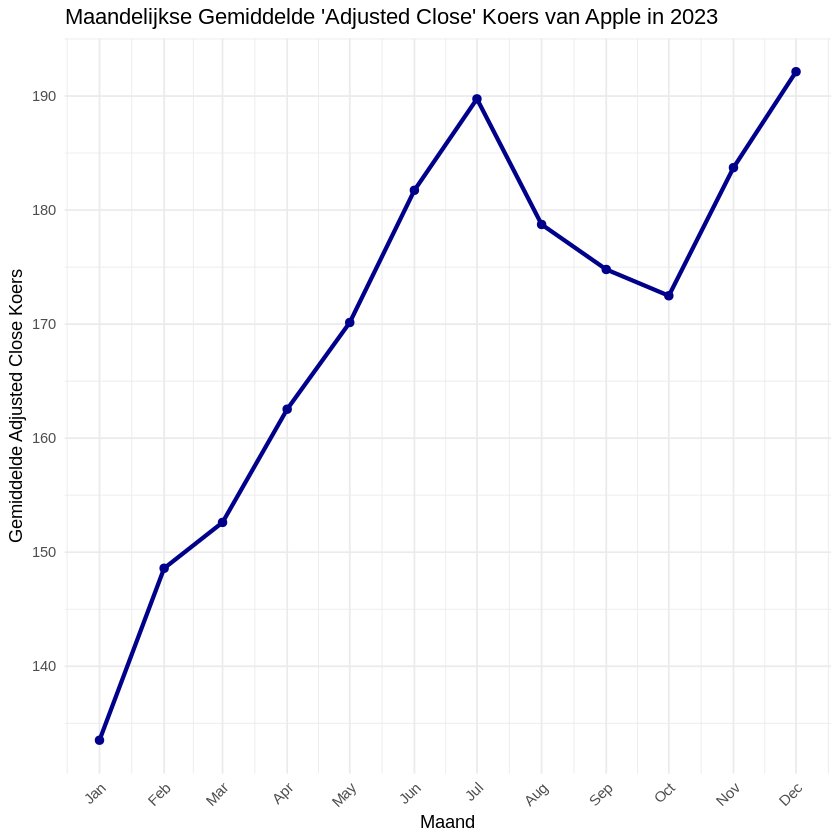

In [22]:
ggplot(aapl_2023_monthly_avg, aes(x = month, y = average_adjusted_close)) +
  geom_line(color = "darkblue", linewidth = 1.2) +
  geom_point(color = "darkblue", size = 2) +
  labs(
    title = "Maandelijkse Gemiddelde 'Adjusted Close' Koers van Apple in 2023",
    x = "Maand",
    y = "Gemiddelde Adjusted Close Koers"
  ) +
  theme_minimal() +
  scale_x_date(date_breaks = "1 month", date_labels = "%b") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))